# 3 · Misura dei solidi

Per ogni solido: scansione della lama (punti 3D in mm), profilo `altezza = 350 − z` rispetto al piano di appoggio (livellato con una retta stimata sui punti più bassi), e quote confrontate con il profilo nominale dei solidi (`lightsheet3d.solids`, ricavato dalle quote dei disegni del corso).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd()
IMAGES, FIGURES = ROOT / "images", ROOT / "docs" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

from lightsheet3d.measure import level_to_plate, measure_peaks
from lightsheet3d.pipeline import PLATE_Z, calibrate_camera, calibrate_light_plane, scan_points
from lightsheet3d.report import compare_profile
from lightsheet3d.solids import SOLIDS as NOMINAL


In [2]:
camera = calibrate_camera(IMAGES / "target")
lp = calibrate_light_plane(IMAGES / "lama", camera.model)

# disegno: altezza dei picchi (mm) e inclinazione dei fianchi (gradi, sx/dx) = 180° - angolo esterno quotato
SOLIDS = {
    "Corpo 6 (30o34)": {"solid": "corpo6", "image": "30o34", "heights": [45, 25, 45], "angles": [(60, 75), (70, 65), (80, 55)]},
    "Corpo 5 (30o3)": {"solid": "corpo5", "image": "30o3", "heights": [35, 30, 45], "angles": None},
}

profiles = {}
for name, s in SOLIDS.items():
    X = scan_points(IMAGES / "oggetto" / f"{s['image']}.jpg", camera.model, lp.plane)
    y = X[:, 1]
    profiles[name] = (y, level_to_plate(y, PLATE_Z - X[:, 2]))
    print(f"{name}: {len(X)} punti 3D")

Corpo 6 (30o34): 1390 punti 3D
Corpo 5 (30o3): 1375 punti 3D


## Profili

Corpo 6 (30o34): distanza dal profilo nominale mediana 0.53 mm, rms 1.04 mm, 90° percentile 1.45 mm (563 punti)


Corpo 5 (30o3): distanza dal profilo nominale mediana 0.69 mm, rms 1.14 mm, 90° percentile 1.93 mm (401 punti)


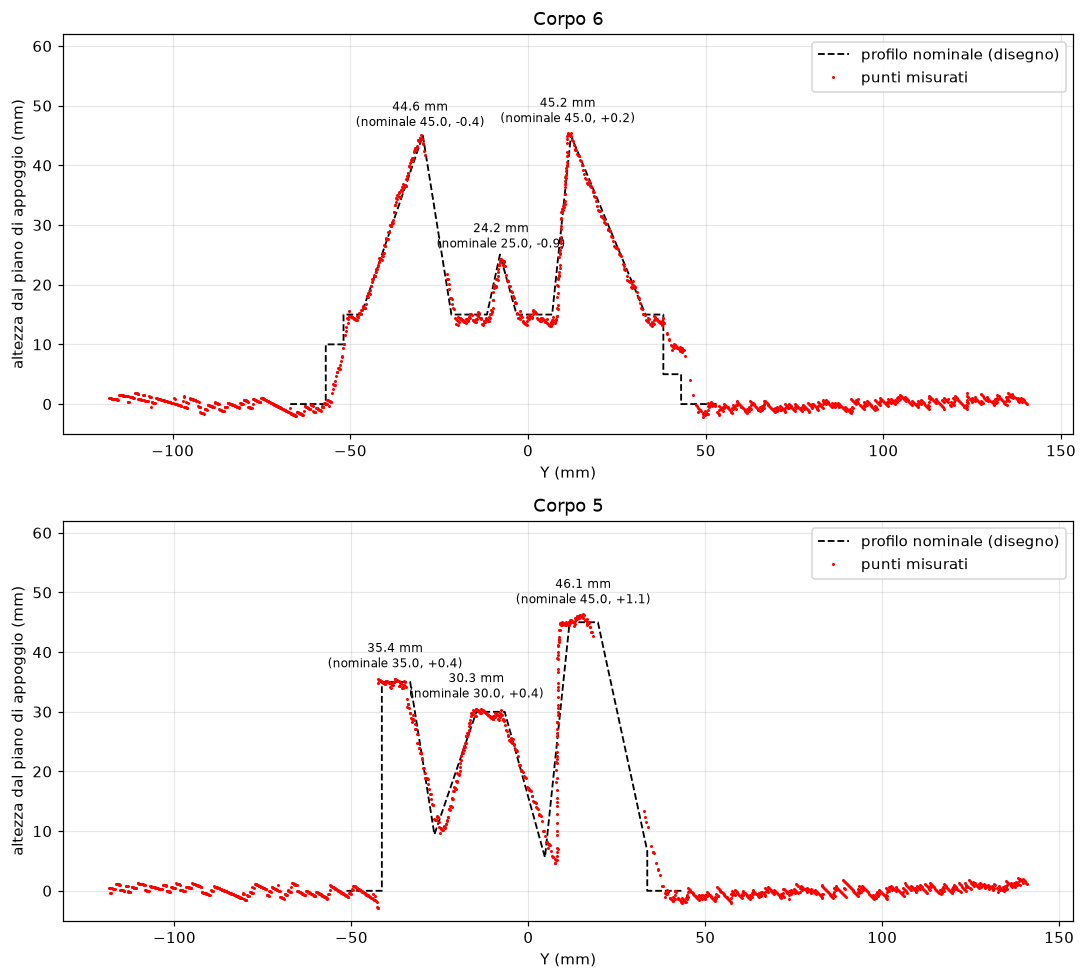

In [3]:
fig, axs = plt.subplots(len(profiles), 1, figsize=(10, 4.5 * len(profiles)))
stats = {}
for ax, (name, (y, h)) in zip(axs, profiles.items()):
    peaks = measure_peaks(y, h, prominence=6, min_separation=10)
    stats[name] = compare_profile(ax, NOMINAL[SOLIDS[name]["solid"]], y, h, peaks)
    print(f"{name}: distanza dal profilo nominale mediana {stats[name]['median']:.2f} mm, rms {stats[name]['rms']:.2f} mm, 90° percentile {stats[name]['p90']:.2f} mm ({stats[name]['points']} punti)")
fig.tight_layout(); fig.savefig(FIGURES / "03_profili.png", bbox_inches="tight")

## Quote misurate e confronto con il disegno

In [4]:
for name, s in SOLIDS.items():
    y, h = profiles[name]
    peaks = measure_peaks(y, h, prominence=6, min_separation=10)
    print(f"\n{name}")
    print(f"  base di appoggio dopo il livellamento: {h[np.abs(h) < 3].mean():+.2f} ± {h[np.abs(h) < 3].std():.2f} mm (media ± dev. std.)")
    errs = []
    for i, p in enumerate(peaks):
        exp = s["heights"][i] if i < len(s["heights"]) else float("nan")
        errs.append(p.height - exp)
        ang = f"fianchi sx/dx {p.left_angle:5.1f}° / {p.right_angle:5.1f}°"
        if s["angles"]: ang += f"  (disegno {s['angles'][i][0]}° / {s['angles'][i][1]}°)"
        print(f"  picco {i + 1}: y = {p.y:6.1f} mm  altezza {p.height:5.1f} mm  (disegno {exp} mm)  {ang}")
    print(f"  errore di altezza: media {np.nanmean(errs):+.2f} mm, dev. std. {np.nanstd(errs):.2f} mm")


Corpo 6 (30o34)
  base di appoggio dopo il livellamento: -0.01 ± 0.80 mm (media ± dev. std.)
  picco 1: y =  -30.3 mm  altezza  44.6 mm  (disegno 45 mm)  fianchi sx/dx  62.6° /   nan°  (disegno 60° / 75°)
  picco 2: y =   -7.6 mm  altezza  24.2 mm  (disegno 25 mm)  fianchi sx/dx  70.7° /  60.6°  (disegno 70° / 65°)
  picco 3: y =   11.2 mm  altezza  45.2 mm  (disegno 45 mm)  fianchi sx/dx  83.6° /  54.1°  (disegno 80° / 55°)
  errore di altezza: media -0.35 mm, dev. std. 0.42 mm

Corpo 5 (30o3)
  base di appoggio dopo il livellamento: -0.02 ± 0.78 mm (media ± dev. std.)
  picco 1: y =  -37.6 mm  altezza  35.4 mm  (disegno 35 mm)  fianchi sx/dx   nan° /  68.4°
  picco 2: y =  -14.7 mm  altezza  30.3 mm  (disegno 30 mm)  fianchi sx/dx  69.4° /  57.8°
  picco 3: y =   15.5 mm  altezza  46.1 mm  (disegno 45 mm)  fianchi sx/dx  88.4° /   nan°
  errore di altezza: media +0.63 mm, dev. std. 0.36 mm


## Limiti del setup

* **Fianchi non illuminati.** I fianchi molto ripidi o rivolti dal lato opposto alla lama non ricevono luce visibile alla camera: nel Corpo 6 manca il fianco destro del primo picco (`nan`) e i bordi verticali hanno pochi punti. La posizione e l'orientamento del solido rispetto alla lama determinano quali tratti si misurano.
* **Quote in altezza.** Errore di ~0.5–1 mm sui picchi, con deviazione standard della base di ~0.8 mm: è il rumore del setup (master e supporto non perfettamente stabili tra gli scatti), non della ricostruzione.
* **Campionamento.** I punti sono uniformi in `v` (righe dell'immagine): i fianchi ripidi hanno pochi punti per mm di altezza e l'apice dei picchi acuti è sottostimato di fino a ~0.5 mm.
* **Zona utile.** Il master copre una porzione dell'immagine; solidi più alti di `z = 350 mm − 50 mm` escono dal volume tarato.